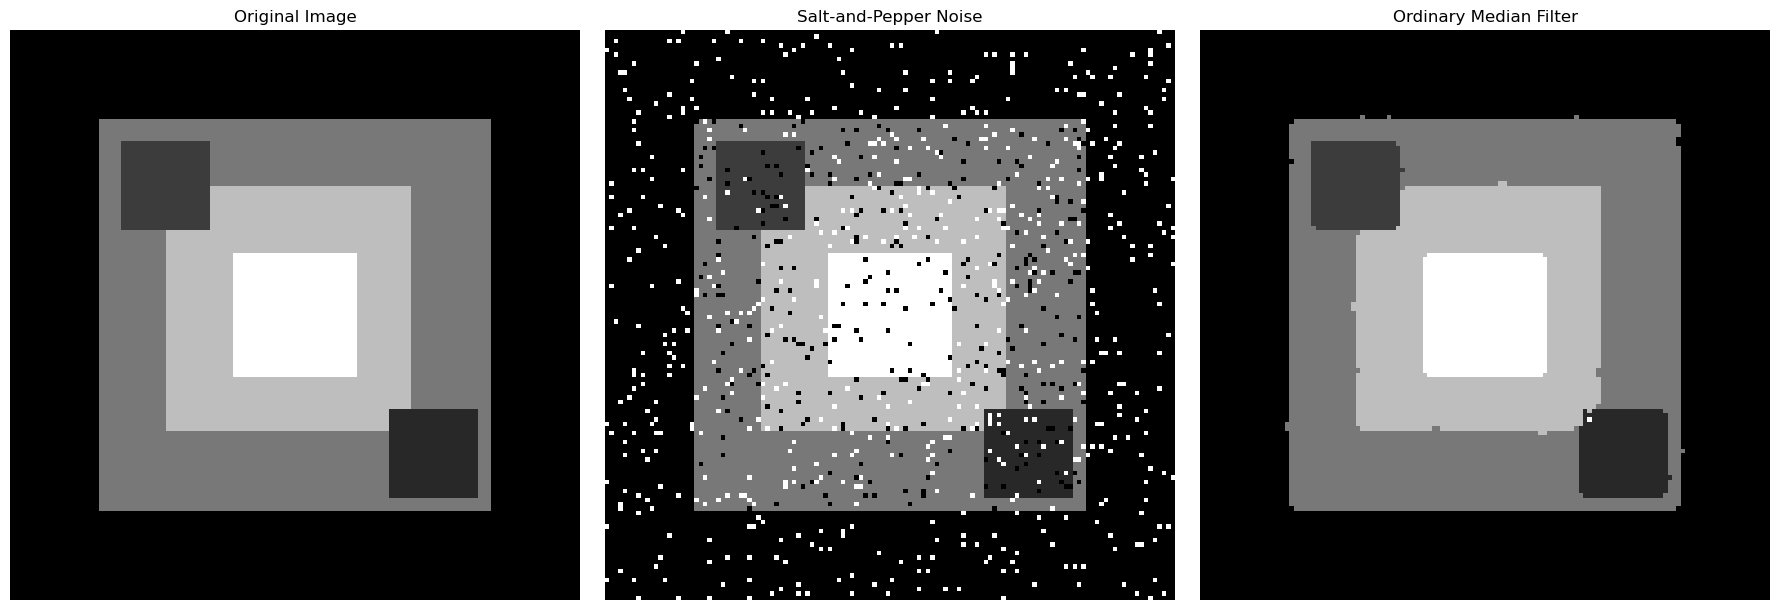

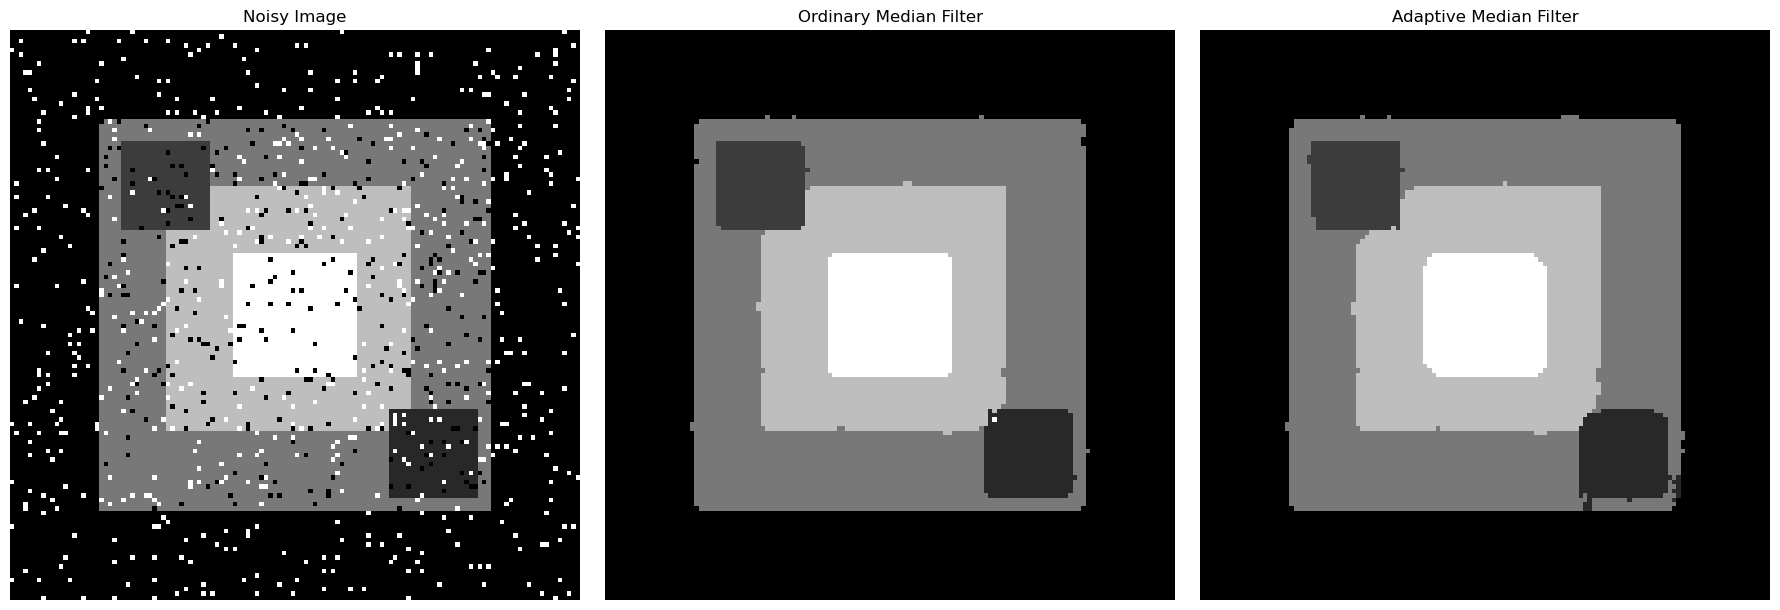

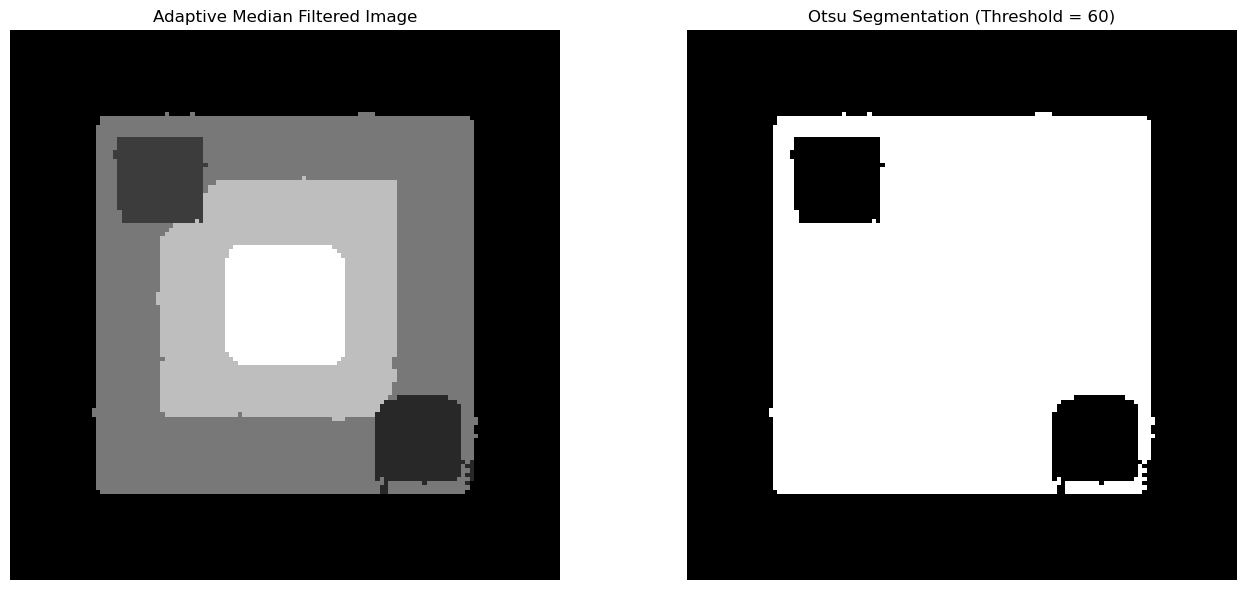

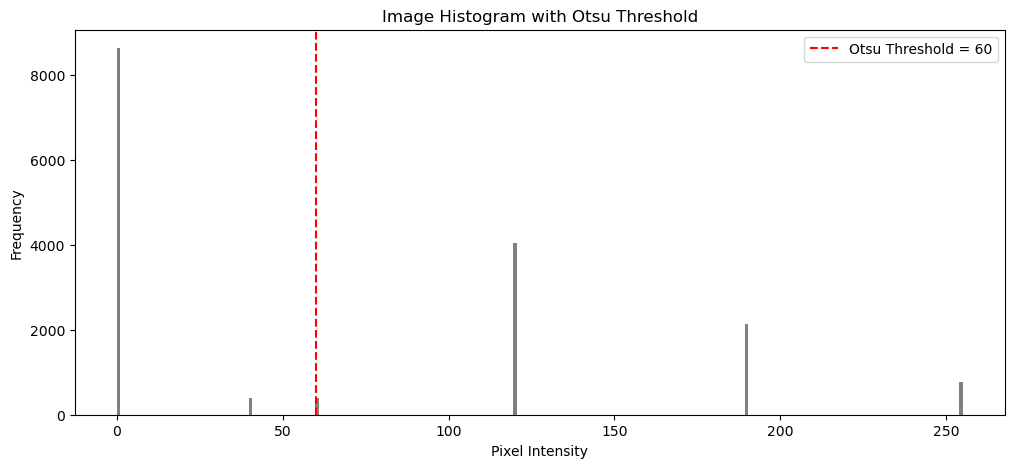

PSNR COMPARISON
---------------------------------------------
Noisy Image:          14.99 dB
Ordinary Median:      33.33 dB
Adaptive Median:      31.09 dB
---------------------------------------------

Smin: 3
Smax: 7
Otsu Threshold: 60


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

rng = np.random.default_rng(42)

# Generate synthetic grayscale image
size = 128
image = np.zeros((size, size), dtype=np.uint8)

image[20:108, 20:108] = 120
image[35:90, 35:90] = 190
image[50:78, 50:78] = 255
image[25:45, 25:45] = 60
image[85:105, 85:105] = 40

# Add salt-and-pepper noise
noisy_image = image.copy()

noise_probability = 0.08
random_values = rng.random(image.shape)

noisy_image[random_values < noise_probability / 2] = 0
noisy_image[
    (random_values >= noise_probability / 2) &
    (random_values < noise_probability)
] = 255


# PSNR calculation
def calculate_psnr(original, processed):
    mse = np.mean(
        (original.astype(float) - processed.astype(float)) ** 2
    )

    if mse == 0:
        return float("inf")

    return 10 * np.log10((255 ** 2) / mse)


# Ordinary median filter
def ordinary_median_filter(img, size=3):
    return median_filter(img, size=size, mode="reflect")


# Adaptive median filter
def adaptive_median_filter(img, Smin=3, Smax=7):
    if Smin < 3 or Smin % 2 == 0:
        raise ValueError("Smin must be an odd number of at least 3.")

    if Smax < Smin or Smax % 2 == 0:
        raise ValueError("Smax must be odd and greater than or equal to Smin.")

    padded = np.pad(img, Smax // 2, mode="reflect")
    output = np.zeros_like(img)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            pixel = padded[i + Smax // 2, j + Smax // 2]
            window_size = Smin
            replacement = pixel

            while window_size <= Smax:

                radius = window_size // 2

                region = padded[
                    i + Smax // 2 - radius:i + Smax // 2 + radius + 1,
                    j + Smax // 2 - radius:j + Smax // 2 + radius + 1
                ]

                z_min = np.min(region)
                z_max = np.max(region)
                z_med = np.median(region)

                # Stage A
                if z_min < z_med < z_max:

                    # Stage B
                    if z_min < pixel < z_max:
                        replacement = pixel
                    else:
                        replacement = z_med

                    break

                window_size += 2

            if window_size > Smax:
                replacement = z_med

            output[i, j] = replacement

    return output.astype(np.uint8)


# Otsu global thresholding
def otsu_threshold(img):
    histogram = np.bincount(img.ravel(), minlength=256)

    total_pixels = img.size
    total_sum = np.dot(np.arange(256), histogram)

    weight_background = 0
    sum_background = 0
    max_variance = 0
    threshold = 0

    for t in range(256):

        weight_background += histogram[t]

        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background

        if weight_foreground == 0:
            break

        sum_background += t * histogram[t]

        mean_background = sum_background / weight_background
        mean_foreground = (
            total_sum - sum_background
        ) / weight_foreground

        between_class_variance = (
            weight_background *
            weight_foreground *
            (mean_background - mean_foreground) ** 2
        )

        if between_class_variance > max_variance:
            max_variance = between_class_variance
            threshold = t

    return threshold


# Input parameters
Smin = 3
Smax = 7

# Apply filters
median_result = ordinary_median_filter(noisy_image, 3)

adaptive_result = adaptive_median_filter(
    noisy_image,
    Smin=Smin,
    Smax=Smax
)

# Apply Otsu thresholding
threshold = otsu_threshold(adaptive_result)

segmented_image = (
    adaptive_result > threshold
).astype(np.uint8) * 255


# Display original and noisy images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [
    (image, "Original Image"),
    (noisy_image, "Salt-and-Pepper Noise"),
    (median_result, "Ordinary Median Filter")
]

for ax, (img, title) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Compare ordinary and adaptive median filtering
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [
    (noisy_image, "Noisy Image"),
    (median_result, "Ordinary Median Filter"),
    (adaptive_result, "Adaptive Median Filter")
]

for ax, (img, title) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Display Otsu segmentation
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(adaptive_result, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Adaptive Median Filtered Image")
axes[0].axis("off")

axes[1].imshow(segmented_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Otsu Segmentation (Threshold = {threshold})")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# Display histogram and Otsu threshold
plt.figure(figsize=(12, 5))

plt.hist(
    adaptive_result.ravel(),
    bins=256,
    range=(0, 255),
    color="gray"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Otsu Threshold = {threshold}"
)

plt.title("Image Histogram with Otsu Threshold")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()


# PSNR comparison
psnr_noisy = calculate_psnr(image, noisy_image)
psnr_median = calculate_psnr(image, median_result)
psnr_adaptive = calculate_psnr(image, adaptive_result)

print("PSNR COMPARISON")
print("-" * 45)
print(f"Noisy Image:          {psnr_noisy:.2f} dB")
print(f"Ordinary Median:      {psnr_median:.2f} dB")
print(f"Adaptive Median:      {psnr_adaptive:.2f} dB")
print("-" * 45)

print(f"\nSmin: {Smin}")
print(f"Smax: {Smax}")
print(f"Otsu Threshold: {threshold}")